# Task 1.4: Is the OD error different with the 50 µL tip than with the 20 µL tip?

Draft. Uses the Monte Carlo process model of task 1.3 (`OD_Norm-MonteCarlo.ipynb`).

**Scenario.** A plate is normalized with the 20 µL tip or with the 50 µL tip (same 1–50 µL pipette). The 50 µL tip needs fewer dispenses (2 × 50 µL transfer instead of 5 × 20 µL), but its spec errors differ. Does the tip change how far the wells land from the target?

**Measurand.** The OD error of each well after round 1, $e = C_{final} - C_{target}$ (OD).

**Hypotheses** (about the spread of $e$; the shared bias cancels, so both means are about 0):

- $H_0$: $\sigma_{50}^2 = \sigma_{20}^2$, the OD error has the same variance with either tip.
- $H_1$: $\sigma_{50}^2 \neq \sigma_{20}^2$.

**Test.** Levene's test (section 5).

**Data.** Simulated: one 96-well plate per tip, the same starting ODs for both tips, so the tips are compared well by well. $n = 96$ per tip, $\alpha = 0.05$. Spec errors: the worst-case rows (assignment assumption 1).

## 1. Plate of starting ODs (same as task 1.3)

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

from od_norm import normalize_plate, plot_od_flow, plot_volume_flow  # simulation loop and flow figures (src/od_norm.py)

np.random.seed(42)
FIG = Path("../figures")  # saved figures for the report (Part1/figures)
FIG.mkdir(parents=True, exist_ok=True)

plate = np.random.uniform(low=1.05, high=1.8, size=(8, 12))  # C_0 per well
C_target = 1.0
V_transfer = 100.0  # nominal transfer volume (uL)
alpha = 0.05
n = plate.size

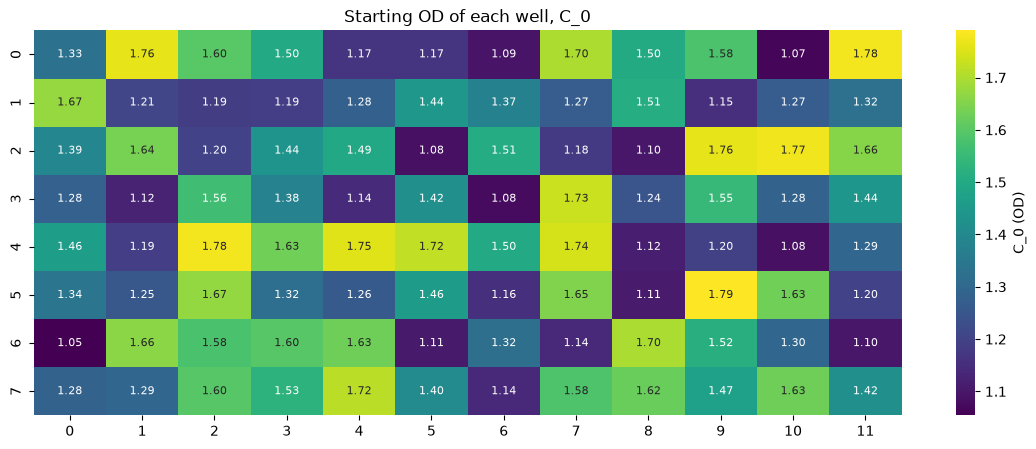

In [2]:
plt.figure(figsize=(14, 5))
sns.heatmap(plate, annot=True, fmt=".2f", annot_kws={"size": 8}, cmap="viridis",
            cbar_kws={"label": "C_0 (OD)"})
plt.title("Starting OD of each well, C_0")
plt.savefig(FIG / "1-4_starting-od.png", dpi=200, bbox_inches="tight")
plt.show()

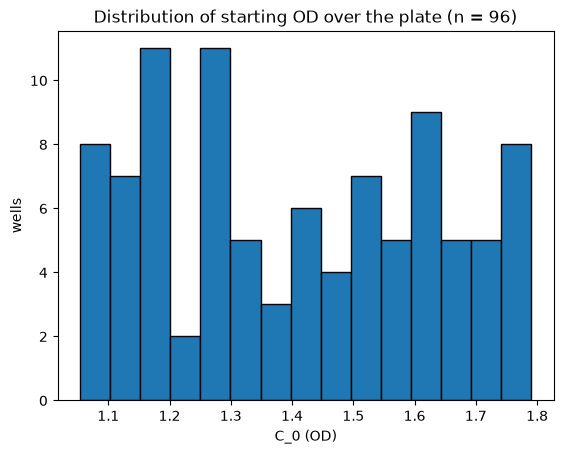

In [3]:
# dist of starting od
plt.hist(plate.ravel(), bins=15, edgecolor="k")
plt.xlabel("C_0 (OD)");
plt.ylabel("wells");
plt.title(f"Distribution of starting OD over the plate (n = {n})")
plt.savefig(FIG / "1-4_starting-od-distribution.png", dpi=200, bbox_inches="tight")
plt.show()

## 2. Spec errors for each tip (worst case)

Assignment assumption 1: each tip's 1 µL row for every dispense. 20 µL tip: 3.5 % CV, ±8 %. 50 µL tip: 7.0 % CV, ±8 %.

In [4]:
specs = {20.0: (0.035, 0.08), 50.0: (0.070, 0.08)}  # tip (uL) -> (err_rand, err_sys)

## 3. Simulate one plate with each tip

How the OD error of one well is calculated, for one plate run (`normalize_plate` in `src/od_norm.py`):

1. Draw one pipette bias $b \sim$ Uniform$(-a, a)$ for the whole plate (every dispense of that run shares it).
2. Dispense plan for the well: the media dose $\tilde V_d = \tilde V_{transfer}(C_0/C_{target}-1)$; split the 100 µL transfer and $\tilde V_d$ into dispenses no larger than the tip.
3. Each dispense delivers $\tilde v\,(1 + b + \varepsilon_{random})$ with its own $\varepsilon_{random} \sim$ Normal$(0, \text{CV})$. Sum them to get the true culture volume $V_{transfer}$ and the true media volume $V_d$.
4. Mass balance: $C_{final} = C_0 V_{transfer} / (V_{transfer} + V_d)$.
5. OD error: $e = C_{final} - C_{target}$.

In [5]:
C_final, V_t, V_d, e = {}, {}, {}, {}  # tip -> 8 x 12 plate of C_final, culture volume, media volume, OD error
for tip in (20.0, 50.0):
    err_rand, err_sys = specs[tip]
    C_final[tip], V_t[tip], V_d[tip] = [r[0] for r in
                                        normalize_plate(plate, tip, err_rand,
                                                        err_sys)]  # one plate run
    e[tip] = C_final[tip] - C_target

pd.DataFrame({
    "mean e (OD)"               : {t: e[t].mean() for t in e},
    "sd e (OD)"                 : {t: e[t].std(ddof=1) for t in e},
    "wells outside 1.0 +/- 0.02": {t: np.sum(np.abs(e[t]) > 0.02) for t in e}}
).rename_axis("tip (uL)").round(5)

,mean e (OD),sd e (OD),wells outside 1.0 +/- 0.02
tip (uL),,,
20.0,-0.00073,0.00635,0
50.0,0.00034,0.02225,36


## 4. The two plates: transfer, then round-1 dilution

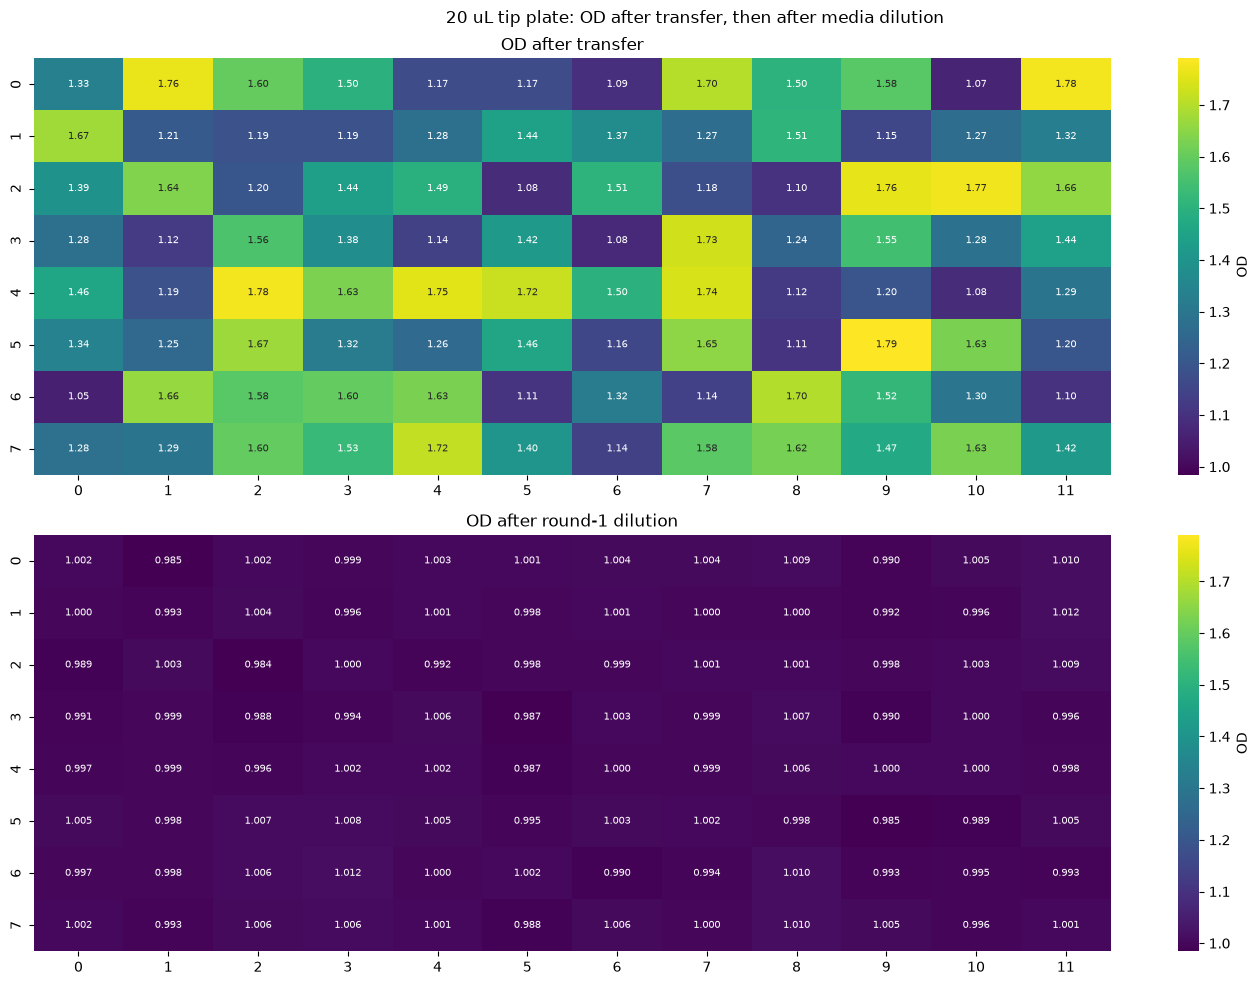

In [6]:
plot_od_flow(plate, C_final[20.0], "20 uL tip plate: OD after transfer, then after media dilution",
             save=FIG / "1-4_od-flow-20uL.png")

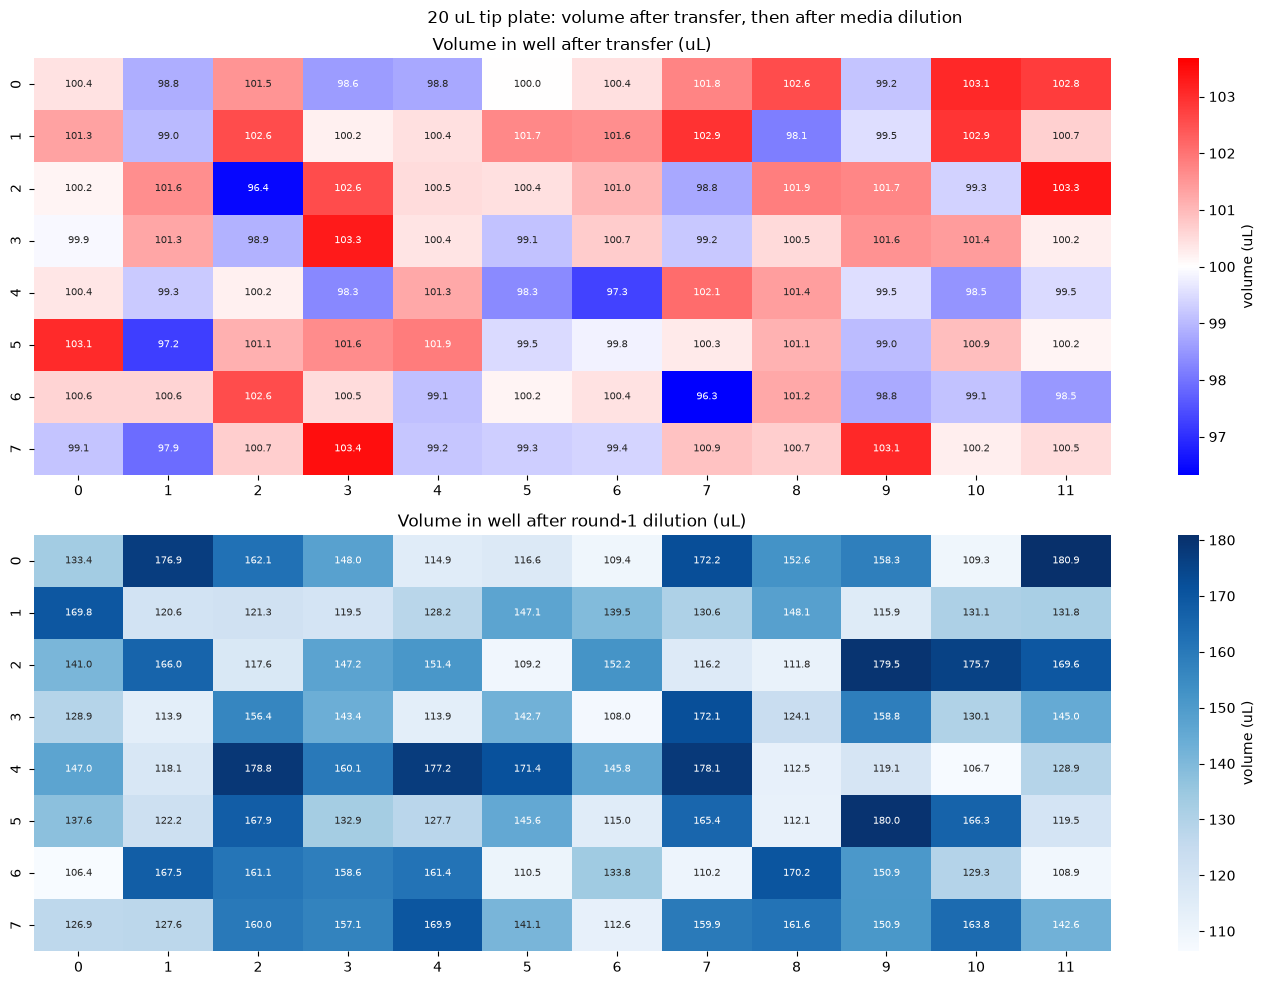

In [7]:
plot_volume_flow(V_t[20.0], V_d[20.0], V_transfer,
                 "20 uL tip plate: volume after transfer, then after media dilution",
                 save=FIG / "1-4_volume-flow-20uL.png")

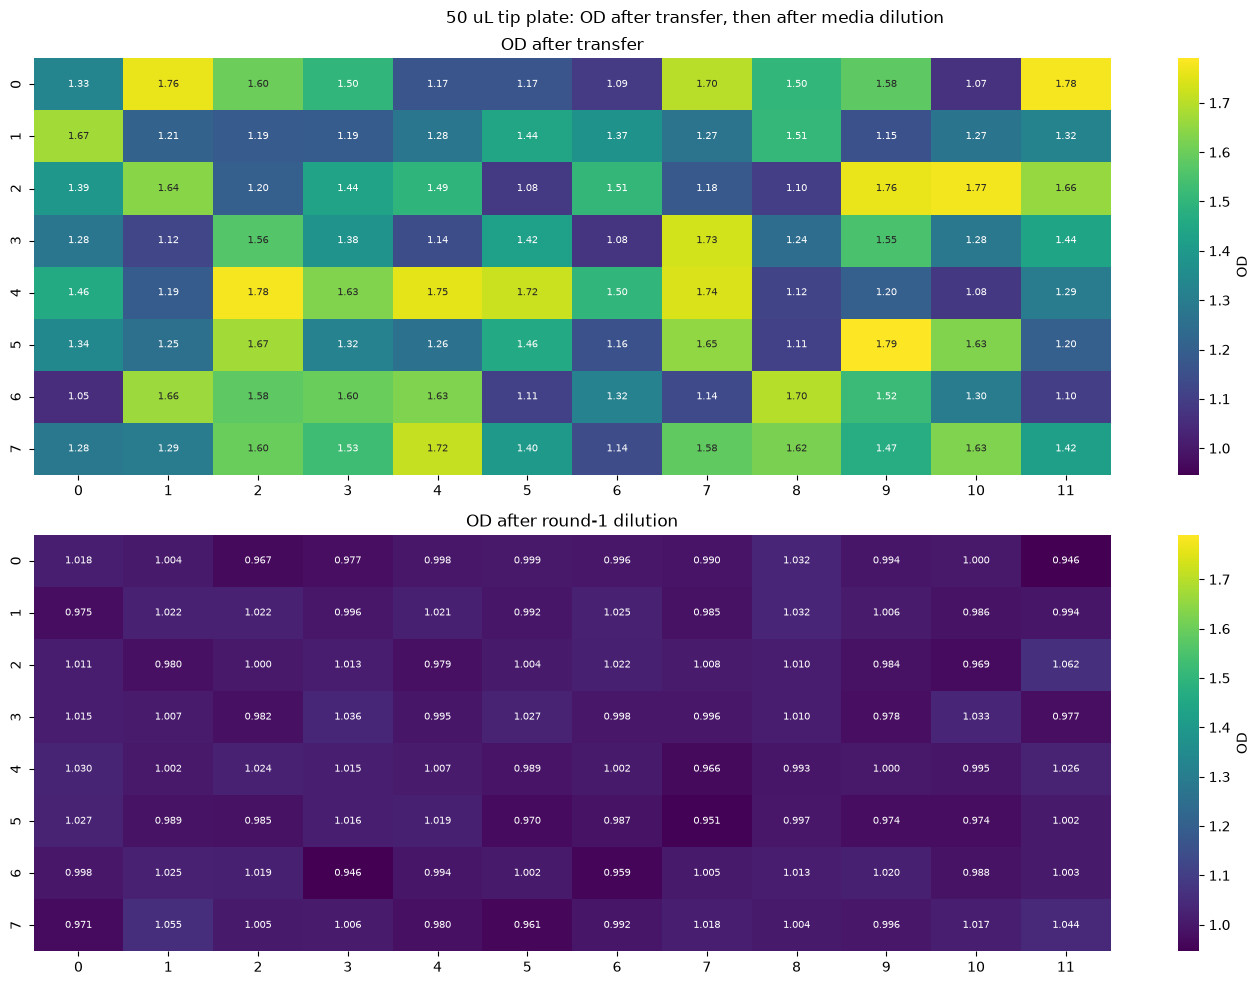

In [8]:
plot_od_flow(plate, C_final[50.0], "50 uL tip plate: OD after transfer, then after media dilution",
             save=FIG / "1-4_od-flow-50uL.png")

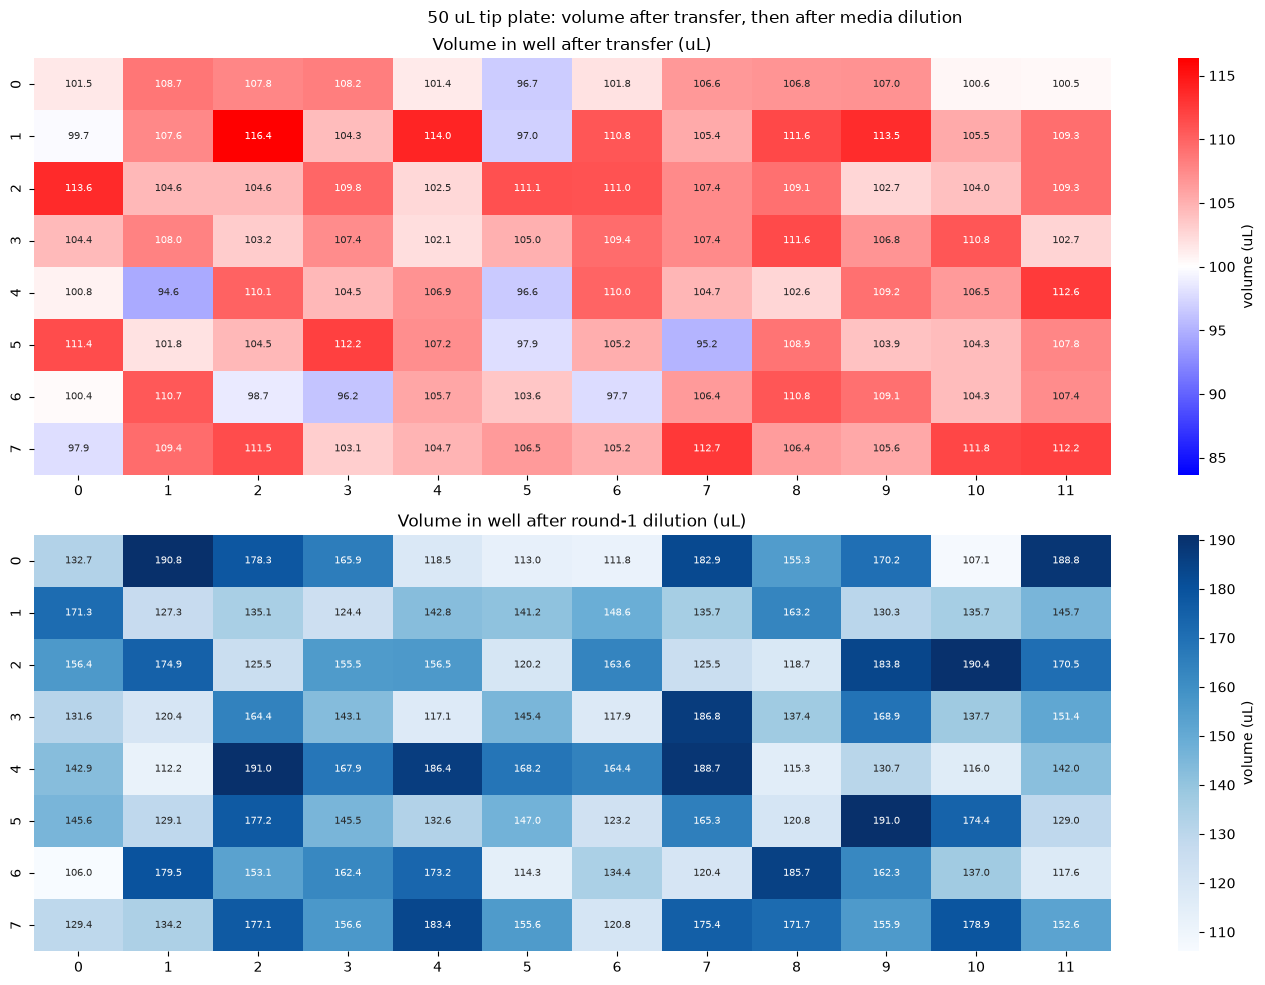

In [9]:
plot_volume_flow(V_t[50.0], V_d[50.0], V_transfer,
                 "50 uL tip plate: volume after transfer, then after media dilution",
                 save=FIG / "1-4_volume-flow-50uL.png")

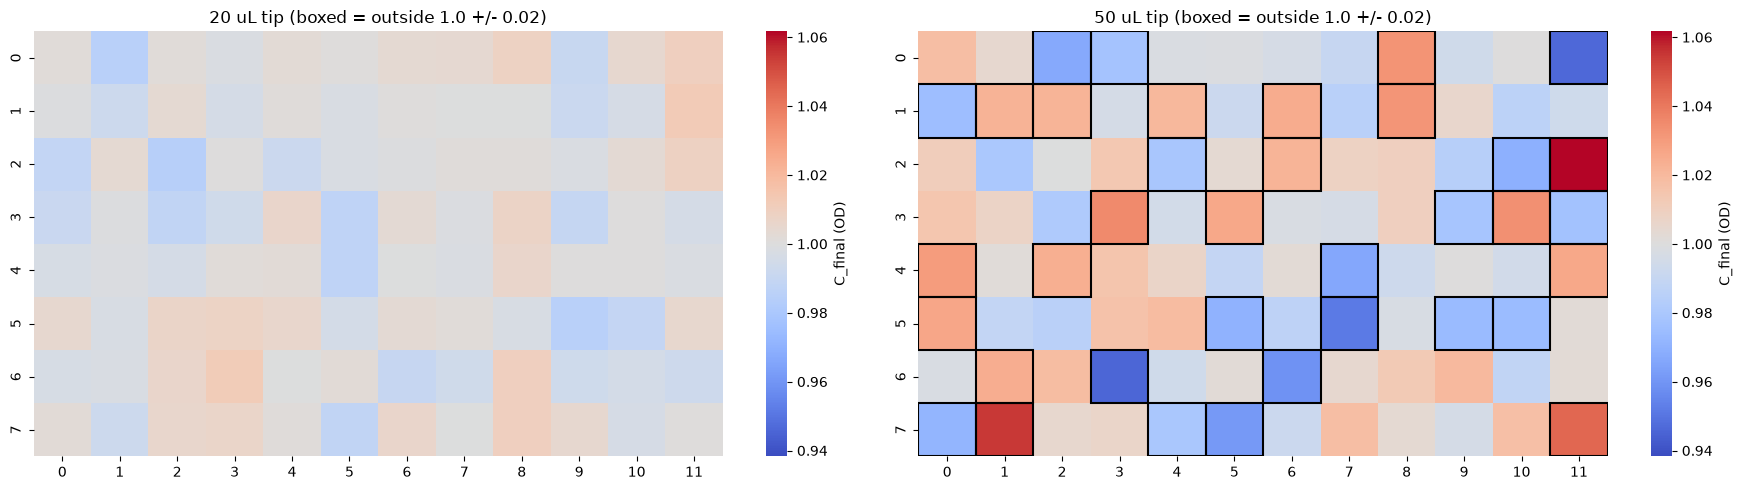

In [10]:
lim = max(np.abs(e[20.0]).max(),
          np.abs(e[50.0]).max())  # same colour scale for both plates
fig, ax = plt.subplots(1, 2, figsize=(18, 5))
for k, tip in enumerate((20.0, 50.0)):
    sns.heatmap(C_final[tip], cmap="coolwarm", center=C_target, vmin=C_target - lim,
                vmax=C_target + lim,
                ax=ax[k], cbar_kws={"label": "C_final (OD)"})
    for i, j in zip(*np.where(np.abs(e[tip]) > 0.02)):
        ax[k].add_patch(plt.Rectangle((j, i), 1, 1, fill=False, ec="k", lw=1.5))
    ax[k].set_title(f"{tip:.0f} uL tip (boxed = outside 1.0 +/- 0.02)")
plt.tight_layout()
plt.savefig(FIG / "1-4_cfinal-plates.png", dpi=200, bbox_inches="tight")
plt.show()

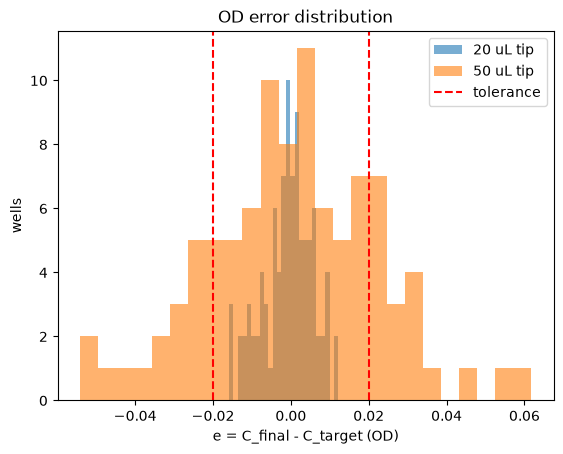

In [11]:
for tip in (20.0, 50.0):
    plt.hist(e[tip].ravel(), bins=25, alpha=0.6, label=f"{tip:.0f} uL tip")
plt.axvline(-0.02, color="r", ls="--")
plt.axvline(0.02, color="r", ls="--", label="tolerance")
plt.xlabel("e = C_final - C_target (OD)")
plt.ylabel("wells")
plt.legend()
plt.title("OD error distribution")
plt.savefig(FIG / "1-4_od-error-distribution.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Levene's test

**Hypotheses** ($\sigma^2$ = variance of the OD error $e$)

- $H_0$: $\sigma_{50}^2 = \sigma_{20}^2$, no difference in variance between the tips
- $H_1$: $\sigma_{50}^2 \neq \sigma_{20}^2$

**Calculation**

1. Absolute deviation of each well from its tip's mean: $z_{ij} = |e_{ij} - \bar e_i|$, tip $i \in \{20, 50\}$, well $j = 1, \dots, n$
2. One-way ANOVA $F$ on $z$:
$$W = \frac{(N - k)\sum_i n\,(\bar z_i - \bar z)^2}{(k - 1)\sum_i \sum_j (z_{ij} - \bar z_i)^2}, \qquad k = 2 \text{ tips}, \quad N = 2n = 192$$

    - $\bar z_i$: mean $z$ of tip $i$
    - $\bar z$: mean $z$ over both tips
   - larger variance → larger $\bar z_i$, so a difference in $\bar z_i$ is a difference in variance


**Test**

- Under $H_0$: $W \sim F(k - 1, N - k) = F(1, 190)$
- $p = P(F_{1,190} \ge W)$, upper tail
- Reject $H_0$ if $p < \alpha = 0.05$, equivalently $W > F_{0.95}(1, 190) = 3.89$

**Assumptions**

| Assumption | Holds here? |
|---|---|
| Observations independent within each tip | Approximately: wells on one plate share one pipette bias, which cancels at first order |
| Observations independent between the tips | Approximately: each plate is a separate run with its own bias and random errors; only the $C_0$ of each well is shared |

Normality is not required, which is why Levene's test is used instead of the variance-ratio F test.

In [12]:

x = np.stack([e[20.0].ravel(),
              e[50.0].ravel()])  # (2, n) observed OD errors, one row per tip
z = np.abs(x - x.mean(axis=1, keepdims=True))  # z_ij = |e_ij - mean e_i|
W_obs, p_lev = stats.levene(x[0], x[1], center="mean")
W_crit = stats.f.ppf(1 - alpha, 1, 2 * n - 2)  # upper 5 % point of F(1, 190)
pd.DataFrame({"value": [round(z[0].mean(), 5), round(z[1].mean(), 5), round(W_obs, 2),
                        round(W_crit, 2),
                        f"{p_lev:.2g}"]},
             index=["mean z, 20 uL tip (OD)", "mean z, 50 uL tip (OD)", "Levene W",
                    "critical value, F(1, 190) at alpha = 0.05", "p (Levene)"])

,value
"mean z, 20 uL tip (OD)",0.00498
"mean z, 50 uL tip (OD)",0.01725
Levene W,69.02
"critical value, F(1, 190) at alpha = 0.05",3.89
p (Levene),1.8e-14


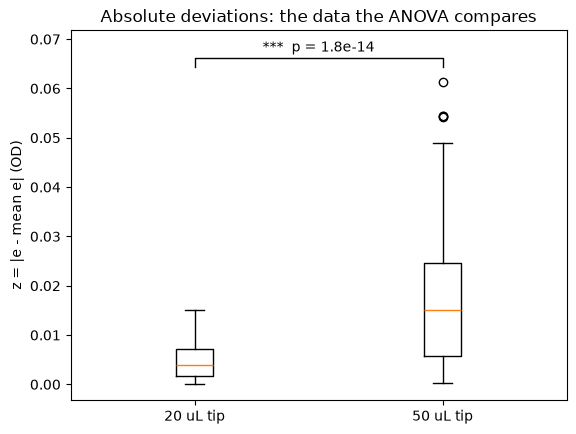

In [13]:
plt.boxplot([z[0], z[1]], tick_labels=["20 uL tip", "50 uL tip"])
plt.ylabel("z = |e - mean e| (OD)")
plt.title("Absolute deviations: the data the ANOVA compares")

# significance bracket between the two boxes (ggsignif style)
y, h = 1.05 * z.max(), 0.03 * z.max()
stars = "***" if p_lev < 0.001 else "**" if p_lev < 0.01 else "*" if p_lev < 0.05 else "ns"
plt.plot([1, 1, 2, 2], [y, y + h, y + h, y], "k", lw=1)
plt.text(1.5, y + 1.3 * h, f"{stars}  p = {p_lev:.2g}", ha="center", va="bottom")
plt.ylim(top=y + 4 * h)
plt.savefig(FIG / "1-4_levene-abs-deviations.png", dpi=200, bbox_inches="tight")
plt.show()

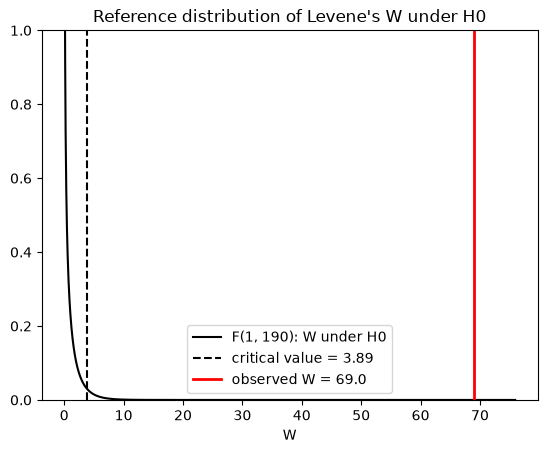

In [14]:
w = np.linspace(0.01, 1.1 * max(W_obs, W_crit), 2000)
plt.plot(w, stats.f.pdf(w, 1, 2 * n - 2), "k", label="F(1, 190): W under H0")
plt.axvline(W_crit, color="k", ls="--", label=f"critical value = {W_crit:.2f}")
plt.axvline(W_obs, color="r", lw=2, label=f"observed W = {W_obs:.1f}")
plt.ylim(0, 1)
plt.xlabel("W")
plt.legend()
plt.title("Reference distribution of Levene's W under H0")
plt.savefig(FIG / "1-4_levene-f-distribution.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Result

In [15]:
result = {
    "sd e, 20 uL tip (OD)": round(e[20.0].std(ddof=1), 5),
    "sd e, 50 uL tip (OD)": round(e[50.0].std(ddof=1), 5),
    "Levene W": round(W_obs, 2),
    "critical value F(1, 190)": round(W_crit, 2),
    "p": f"{p_lev:.2g}",
    "decision at alpha = 0.05": "reject H0" if p_lev < alpha else "do not reject H0",
}
pd.DataFrame.from_dict(result, orient="index", columns=["value"])

,value
"sd e, 20 uL tip (OD)",0.00635
"sd e, 50 uL tip (OD)",0.02225
Levene W,69.02
"critical value F(1, 190)",3.89
p,1.8e-14
decision at alpha = 0.05,reject H0


**Interpretation.** $W = 69.0 > 3.89$ ($p = 1.8 \times 10^{-14}$), so $H_0$ is rejected: the variance of the OD error differs between the tips. With the worst-case spec rows, the 50 µL tip's OD error has about 3.5 times the standard deviation (about 3.0 expected from the analytic $u_c$ of each well) of the 20 µL tip's (0.0223 vs 0.0064 OD), and 36 of 96 wells land outside 1.0 ± 0.02 against 0 with the 20 µL tip. Both differences push the same way: the CV doubles (× 2), and fewer, larger dispenses average out less random error (about × 1.5 over the plate). The result holds only under assumption 1: at the volume-matched rows the 50 µL tip's CV (0.4 %) is lower than the 20 µL tip's (0.75 %).